# Explaining the trend and seasonal components of a forecast

A multi-step forecaster returns a whole horizon per example, a tensor of shape `(batch, H)`. Attribution methods explain one
scalar per example, so the usual choice is the mean of the forecast or a single step. Neither says which inputs drive the
*shape* of the forecast, for example its daily cycle.

This tutorial uses an output layer that writes every forecast as the sum of three components in orthogonal subspaces of the
horizon,

$$\hat{\mathbf{y}} = \mathbf{T} + \mathbf{S} + \mathbf{R} \qquad \text{(trend, seasonal, residual)},$$

the **Neural Fourier Head** (NFH) [1]. The three subspaces are orthogonal and together span $\mathbb{R}^H$, so the
decomposition of any forecast is exact and unique. Each component then defines its own scalar, and any Captum attribution
method can explain it. In this notebook we:

1. build the fixed bases of the head and check numerically that the decomposition is unique;
2. generate a multivariate series in which we know which input drives the trend and which drives the daily cycle;
3. train a forecaster with a dense output layer, convert that layer *exactly* into the head and adjust it;
4. read the decomposition of a forecast: components, harmonic amplitudes and energy shares;
5. explain the level of the trend and the energy of the seasonal component with `IntegratedGradients`, check completeness,
   and compare with explaining one scalar of the whole forecast.

The head is written in the notebook; nothing is added to Captum. The notebook runs on a CPU in well under a minute.

[1] R. L. de S. Gaspar and T. A. Rocha, *Neural Fourier Head: an identifiable trend–seasonal decomposition layer for
interpretable multi-step forecasting*, submitted to ESANN 2027 (under review). Reference implementation and experiments:
https://github.com/RicksonLivio/NeuralFourierHead (BSD 3-Clause).

In [1]:
import copy

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn

from captum.attr import IntegratedGradients

torch.manual_seed(0)
rng = np.random.default_rng(0)
DTYPE = torch.float64  # double precision keeps the exactness checks below tight

## 1. The head: three fixed, orthogonal bases

Let $H$ be the horizon, $\tau_j = j/H$ for $j = 0, \dots, H-1$, $q$ the trend degree, $K$ the number of harmonics and
$m = q + 1 + 2K \le H$.

* **Trend basis** $\mathbf{P} \in \mathbb{R}^{(q+1) \times H}$, with $P_{ij} = \tau_j^{\,i}$.
* **Fourier basis** $\mathbf{F} \in \mathbb{R}^{2K \times H}$, with rows $\cos(2\pi k \tau_j)$ and $\sin(2\pi k \tau_j)$,
  $k = 1, \dots, K$.
* **Seasonal basis** $\widetilde{\mathbf{F}} = \mathbf{F}(\mathbf{I} - \Pi_T)$, where $\Pi_T$ projects onto the span of the
  trend basis: each sinusoid without the part that a polynomial of degree $q$ already explains.
* **Residual basis** $\mathbf{Q} \in \mathbb{R}^{H \times (H-m)}$, an orthonormal basis of what the first two do not span.

A linear layer gives coefficients $\mathbf{c} = \mathbf{W}\mathbf{h} + \mathbf{b} \in \mathbb{R}^H$ from the latent vector
$\mathbf{h}$ of the backbone. They are split into $\boldsymbol{\theta}_T$ ($q+1$ values),
$\boldsymbol{\theta}_S = (a_1, b_1, \dots, a_K, b_K)$ (the cosine and sine coefficients of each harmonic) and $\mathbf{u}$
($H - m$ values), and the head outputs

$$\mathbf{T} = \mathbf{P}^\top\boldsymbol{\theta}_T, \quad \mathbf{S} = \widetilde{\mathbf{F}}^\top\boldsymbol{\theta}_S,
\quad \mathbf{R} = \mathbf{Q}\mathbf{u}, \qquad \hat{\mathbf{y}} = \mathbf{M}\mathbf{c}, \quad
\mathbf{M} = [\mathbf{P}^\top\ \widetilde{\mathbf{F}}^\top\ \mathbf{Q}] \in \mathbb{R}^{H \times H}.$$

The amplitude of harmonic $k$ is $A_k = (a_k^2 + b_k^2)^{1/2}$. Here $H = 24$ hours, $q = 2$ and $K = 5$ (periods of
24, 12, 8, 6 and 4.8 hours), so $m = 13$.

In [2]:
def build_bases(horizon: int, degree: int, n_harmonics: int):
    """Return P (q+1, H), F_tilde (2K, H) and Q (H, H-m)."""
    m = degree + 1 + 2 * n_harmonics
    assert m <= horizon, "the head needs m = q + 1 + 2K <= H"
    tau = torch.arange(horizon, dtype=DTYPE) / horizon
    P = torch.stack([tau**i for i in range(degree + 1)])
    k = torch.arange(1, n_harmonics + 1, dtype=DTYPE)[:, None]
    angle = 2 * torch.pi * k * tau
    # rows cos(1), sin(1), cos(2), sin(2), ...: the order of theta_S = (a_1, b_1, ..., a_K, b_K)
    F = torch.stack([torch.cos(angle), torch.sin(angle)], dim=1).reshape(2 * n_harmonics, horizon)
    proj_trend = P.T @ torch.linalg.solve(P @ P.T, P)
    F_tilde = F @ (torch.eye(horizon, dtype=DTYPE) - proj_trend)
    U, _, _ = torch.linalg.svd(torch.cat([P, F]).T, full_matrices=True)
    Q = U[:, m:]  # orthonormal basis of the orthogonal complement
    return P, F_tilde, Q


H, Q_DEG, K_HARM = 24, 2, 5
P, F_tilde, Q = build_bases(H, Q_DEG, K_HARM)
M = torch.cat([P.T, F_tilde.T, Q], dim=1)
SIZES = (P.shape[0], F_tilde.shape[0], Q.shape[1])

print(f"M: {tuple(M.shape)}, rank {torch.linalg.matrix_rank(M).item()}")
orthogonality = {
    "trend . seasonal": (P @ F_tilde.T).abs().max().item(),
    "trend . residual": (P @ Q).abs().max().item(),
    "seasonal . residual": (F_tilde @ Q).abs().max().item(),
}
for pair, value in orthogonality.items():
    print(f"max |{pair}| = {value:.1e}")
assert max(orthogonality.values()) < 1e-10

M: (24, 24), rank 24
max |trend . seasonal| = 9.1e-15
max |trend . residual| = 4.4e-16
max |seasonal . residual| = 1.0e-15


Because $\mathbf{M}$ is invertible and its three blocks are mutually orthogonal, every vector of $\mathbb{R}^H$, and so every
forecast, has exactly one decomposition, obtained with the fixed map $\mathbf{c} = \mathbf{M}^{-1}\hat{\mathbf{y}}$. The
components therefore depend only on the forecast, not on the weights that produced it.

This is not true of every trend + seasonal model. In interpretable N-BEATS, for instance, both the trend basis and the
seasonal basis contain the constant vector: a level shift can be moved from one stack to the other without changing the
forecast, so the split is not unique [1].

In [3]:
def decompose(y_hat: torch.Tensor) -> dict:
    """Unique trend / seasonal / residual split of any forecast of shape (batch, H)."""
    theta_T, theta_S, u = torch.linalg.solve(M, y_hat.T).T.split(SIZES, dim=-1)
    return {"trend": theta_T @ P, "seasonal": theta_S @ F_tilde, "residual": u @ Q.T, "theta_S": theta_S}


y_random = torch.randn(3, H, dtype=DTYPE)
parts = decompose(y_random)
rebuilt = parts["trend"] + parts["seasonal"] + parts["residual"]
print(f"max |T + S + R - y| = {(rebuilt - y_random).abs().max().item():.1e}")
assert torch.allclose(rebuilt, y_random, atol=1e-10)

max |T + S + R - y| = 2.7e-15


## 2. A series with known drivers

The data follow the synthetic SINT-M series of [1], made smaller. There are $d = 4$ hourly input variables:

* $\mathbf{x}_1$, a slow autoregressive process: it drives the **trend**;
* $\mathbf{x}_2$, a daily oscillation with a slowly varying amplitude: it drives the **cycle**;
* $\mathbf{x}_3$ and $\mathbf{x}_4$, distractors of the same two types.

The target is $y_t = x_{1,t-24} + x_{2,t-24} + e_t$, with autoregressive noise $e_t$, and it is **not** an input. As the
delay equals the horizon, the next 24 values of $y$ are set by the last 24 hours of $\mathbf{x}_1$ and $\mathbf{x}_2$, which
are inside the input window of $L = 48$ hours. So we know the right answer: the predicted trend should be attributed to
$\mathbf{x}_1$ and the predicted cycle to $\mathbf{x}_2$.

In [4]:
def ar1(n: int, phi: float, sigma: float) -> np.ndarray:
    z = np.zeros(n)
    noise = rng.normal(0.0, sigma, n)
    for i in range(1, n):
        z[i] = phi * z[i - 1] + noise[i]
    return z


N, L, DELAY = 6000, 48, H
t = np.arange(N)
smooth = np.ones(24) / 24
x1 = np.convolve(ar1(N, 0.998, 0.06), smooth, mode="same")
x3 = np.convolve(ar1(N, 0.998, 0.06), smooth, mode="same")
x2 = np.exp(0.4 * ar1(N, 0.99, 0.14)) * np.sin(2 * np.pi * t / 24 + 0.3)
x4 = np.exp(0.4 * ar1(N, 0.99, 0.14)) * np.sin(2 * np.pi * t / 24 + 1.4)
inputs = np.stack([x1, x2, x3, x4], axis=1)[DELAY:]
target = (x1[:-DELAY] + x2[:-DELAY]) + ar1(N, 0.5, 0.15)[DELAY:]
VARIABLES = ["x1 (trend driver)", "x2 (cycle driver)", "x3 (slow distractor)", "x4 (cycle distractor)"]

# chronological split 70 / 15 / 15; standardize with the training part only
n_train, n_val = int(0.7 * len(target)), int(0.15 * len(target))
mu, sd = inputs[:n_train].mean(0), inputs[:n_train].std(0)
mu_y, sd_y = target[:n_train].mean(), target[:n_train].std()
inputs, target = (inputs - mu) / sd, (target - mu_y) / sd_y


def windows(start: int, stop: int):
    """Input windows (n, L, d) and target horizons (n, H) whose horizon lies in [start, stop)."""
    first = max(start - L, 0)
    idx = np.arange(first, stop - L - H + 1)
    X = np.stack([inputs[i : i + L] for i in idx])
    Y = np.stack([target[i + L : i + L + H] for i in idx])
    return torch.tensor(X, dtype=DTYPE), torch.tensor(Y, dtype=DTYPE)


x_train, y_train = windows(0, n_train)
x_val, y_val = windows(n_train, n_train + n_val)
x_test, y_test = windows(n_train + n_val, len(target))
print("train", tuple(x_train.shape), "validation", tuple(x_val.shape), "test", tuple(x_test.shape))

train (4112, 48, 4) validation (873, 48, 4) test (874, 48, 4)


## 3. Train a dense forecaster, convert it exactly, adjust it

A forecaster is $f = g \circ \Phi$: a backbone $\Phi$ maps the window to $\mathbf{h} \in \mathbb{R}^p$ (here a small MLP on
the flattened window) and $g$ is the output layer. We follow the training procedure of [1]:

1. train the model with an ordinary **dense** output layer $g(\mathbf{h}) = \mathbf{W}_D\mathbf{h} + \mathbf{b}_D$;
2. **convert** it: since $\mathbf{M}$ is invertible, the head with $\mathbf{W} = \mathbf{M}^{-1}\mathbf{W}_D$ and
   $\mathbf{b} = \mathbf{M}^{-1}\mathbf{b}_D$ computes the same function (same forecasts, same parameter count);
3. **adjust** it for a few epochs on
   $\mathcal{J}_\lambda = \mathrm{MSE} + \lambda (MH)^{-1}\sum_{n=1}^{M}\lVert\mathbf{R}(\mathbf{X}^{(n)})\rVert^2$, where
   $\mathbf{X}^{(n)}$ is the $n$-th of the $M$ training windows: the penalty pulls the forecasts towards trend + seasonal;
4. **safe selection**: among the epochs whose validation RMSE is at most that of the dense model, keep the one with the lowest
   validation $\mathcal{J}_\lambda$. Epoch 0 (the converted dense model) always qualifies, so the selected head is never worse
   than the dense model **on validation data**. On test data it can be.

In [5]:
class Backbone(nn.Module):
    def __init__(self, length: int, n_vars: int, hidden: int) -> None:
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(), nn.Linear(length * n_vars, hidden), nn.GELU(), nn.Linear(hidden, hidden), nn.GELU()
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


class DenseHead(nn.Module):
    def __init__(self, hidden: int, horizon: int) -> None:
        super().__init__()
        self.linear = nn.Linear(hidden, horizon)

    def forward(self, h: torch.Tensor) -> dict:
        return {"forecast": self.linear(h)}


class FourierHead(nn.Module):
    """Linear layer c = W h + b followed by the fixed synthesis y = M c, split into T, S and R."""

    def __init__(self, hidden: int) -> None:
        super().__init__()
        self.linear = nn.Linear(hidden, H)
        for name, basis in (("P", P), ("F_tilde", F_tilde), ("Q", Q)):
            self.register_buffer(name, basis.clone())

    @classmethod
    def from_dense(cls, dense: DenseHead) -> "FourierHead":
        head = cls(dense.linear.in_features).to(DTYPE)
        with torch.no_grad():
            head.linear.weight.copy_(torch.linalg.solve(M, dense.linear.weight))
            head.linear.bias.copy_(torch.linalg.solve(M, dense.linear.bias))
        return head

    def forward(self, h: torch.Tensor) -> dict:
        theta_T, theta_S, u = self.linear(h).split(SIZES, dim=-1)
        trend, seasonal, residual = theta_T @ self.P, theta_S @ self.F_tilde, u @ self.Q.T
        return {
            "forecast": trend + seasonal + residual,
            "trend": trend,
            "seasonal": seasonal,
            "residual": residual,
            "theta_S": theta_S,
        }


class Forecaster(nn.Module):
    def __init__(self, backbone: nn.Module, head: nn.Module) -> None:
        super().__init__()
        self.backbone, self.head = backbone, head

    def forward(self, x: torch.Tensor) -> dict:
        return self.head(self.backbone(x))

In [6]:
def objective(model: nn.Module, x: torch.Tensor, y: torch.Tensor, lam: float) -> tuple:
    """Return (RMSE, J_lambda) of the model on (x, y)."""
    out = model(x)
    mse = ((out["forecast"] - y) ** 2).mean()
    penalty = (out["residual"] ** 2).mean() if "residual" in out else torch.zeros((), dtype=DTYPE)
    return mse.sqrt(), mse + lam * penalty


def train(model: nn.Module, epochs: int, lr: float, lam: float = 0.0, batch: int = 64) -> list:
    """Adam on J_lambda. Return the state and the validation (RMSE, J_lambda) after each epoch, epoch 0 included."""
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = []
    for epoch in range(epochs + 1):
        if epoch > 0:
            model.train()
            for idx in torch.randperm(len(x_train)).split(batch):
                optimizer.zero_grad()
                objective(model, x_train[idx], y_train[idx], lam)[1].backward()
                optimizer.step()
        model.eval()
        with torch.no_grad():
            rmse, j_val = objective(model, x_val, y_val, lam)
        state = {k: v.clone() for k, v in model.state_dict().items()}
        history.append({"epoch": epoch, "state": state, "rmse": rmse.item(), "J": j_val.item()})
    return history


# 1. dense model: keep the epoch with the lowest validation RMSE
dense = Forecaster(Backbone(L, 4, 64), DenseHead(64, H)).to(DTYPE)
history = train(dense, epochs=30, lr=1e-3)
best = min(history[1:], key=lambda r: r["rmse"])
dense.load_state_dict(best["state"])
rmse_dense = best["rmse"]

# 2. exact conversion
model = Forecaster(copy.deepcopy(dense.backbone), FourierHead.from_dense(dense.head))
model.eval()
with torch.no_grad():
    conversion_error = (model(x_test)["forecast"] - dense(x_test)["forecast"]).abs().max().item()
print(f"dense validation RMSE {rmse_dense:.4f}; conversion: max |NFH - dense| on test = {conversion_error:.1e}")
assert conversion_error < 1e-10

# 3. structural adjustment and 4. safe selection
LAMBDA = 100.0
adjustment = train(model, epochs=10, lr=1e-4, lam=LAMBDA)
r0 = adjustment[0]["rmse"]  # epoch 0 is the converted dense model (equal to rmse_dense up to rounding)
feasible = [r for r in adjustment if r["rmse"] <= r0]
chosen = min(feasible, key=lambda r: r["J"])
model.load_state_dict(chosen["state"])
model.eval()
print(
    f"selected epoch {chosen['epoch']} of {len(adjustment) - 1}: validation RMSE {chosen['rmse']:.4f} "
    f"(dense {r0:.4f}), validation J {chosen['J']:.4f} (epoch 0: {adjustment[0]['J']:.4f})"
)
assert chosen["rmse"] <= r0

with torch.no_grad():
    rmse_test = {
        "dense": ((dense(x_test)["forecast"] - y_test) ** 2).mean().sqrt().item(),
        "NFH": ((model(x_test)["forecast"] - y_test) ** 2).mean().sqrt().item(),
        "training mean": (y_test**2).mean().sqrt().item(),  # the target is standardized: its training mean is 0
    }

dense validation RMSE 0.1579; conversion: max |NFH - dense| on test = 8.9e-15


selected epoch 10 of 10: validation RMSE 0.1536 (dense 0.1579), validation J 0.0310 (epoch 0: 0.0701)


Test RMSE of the dense model, of the head and of the constant forecast equal to the training mean of the target:

In [7]:
for name, value in rmse_test.items():
    print(f"{name:14s} test RMSE {value:.4f}")

dense          test RMSE 0.1651
NFH            test RMSE 0.1610
training mean  test RMSE 0.9551


## 4. Reading the decomposition of a forecast

The components are part of the forward pass. With $\bar{y}$ the mean of the forecast, $\hat{\mathbf{y}}_c = \hat{\mathbf{y}} -
\bar{y}\mathbf{1}$ and $\mathbf{T}_c = \mathbf{T} - \bar{y}\mathbf{1}$ (the constant is in the trend basis, and $\mathbf{S}$
and $\mathbf{R}$ have zero mean), orthogonality gives
$\lVert\hat{\mathbf{y}}_c\rVert^2 = \lVert\mathbf{T}_c\rVert^2 + \lVert\mathbf{S}\rVert^2 + \lVert\mathbf{R}\rVert^2$. The
shares $\varepsilon_T$, $\varepsilon_S$ and $\varepsilon_R$ of the shape energy are in $[0, 1]$ and add up to one;
$\kappa = 1 - \varepsilon_R$ is the share of the shape explained by trend and seasonality.

In [8]:
with torch.no_grad():
    out = model(x_test)
    centered = out["forecast"] - out["forecast"].mean(dim=1, keepdim=True)
    trend_c = out["trend"] - out["forecast"].mean(dim=1, keepdim=True)
    energy = {
        "T": (trend_c**2).sum(1),
        "S": (out["seasonal"] ** 2).sum(1),
        "R": (out["residual"] ** 2).sum(1),
    }
    total = (centered**2).sum(1)
assert torch.allclose(energy["T"] + energy["S"] + energy["R"], total, rtol=1e-8)
shares = {k: (v / total) for k, v in energy.items()}
print("median energy shares on the test windows: " + ", ".join(f"eps_{k} = {v.median():.3f}" for k, v in shares.items()))
print(f"median coverage kappa = {(1 - shares['R']).median():.3f}")

i = 0
a_k, b_k = out["theta_S"][i, 0::2], out["theta_S"][i, 1::2]
amplitudes = (a_k**2 + b_k**2).sqrt()
for k, amp in enumerate(amplitudes.tolist(), start=1):
    print(f"window {i}: harmonic {k} (period {H / k:4.1f} h) amplitude A_{k} = {amp:.3f}")

median energy shares on the test windows: eps_T = 0.770, eps_S = 0.229, eps_R = 0.000
median coverage kappa = 1.000
window 0: harmonic 1 (period 24.0 h) amplitude A_1 = 1.512
window 0: harmonic 2 (period 12.0 h) amplitude A_2 = 0.007
window 0: harmonic 3 (period  8.0 h) amplitude A_3 = 0.007
window 0: harmonic 4 (period  6.0 h) amplitude A_4 = 0.011
window 0: harmonic 5 (period  4.8 h) amplitude A_5 = 0.013


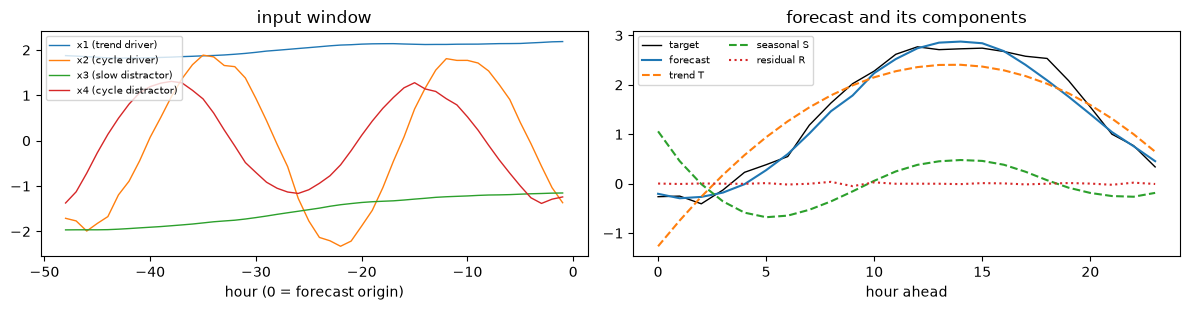

In [9]:
hours_in, hours_out = np.arange(-L, 0), np.arange(H)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
for v, name in enumerate(VARIABLES):
    axes[0].plot(hours_in, x_test[i, :, v].numpy(), label=name, lw=1)
axes[0].set_title("input window")
axes[0].set_xlabel("hour (0 = forecast origin)")
axes[0].legend(fontsize=7, loc="upper left")
axes[1].plot(hours_out, y_test[i].numpy(), color="black", lw=1, label="target")
axes[1].plot(hours_out, out["forecast"][i].numpy(), color="tab:blue", label="forecast")
axes[1].plot(hours_out, out["trend"][i].numpy(), "--", color="tab:orange", label="trend T")
axes[1].plot(hours_out, out["seasonal"][i].numpy(), "--", color="tab:green", label="seasonal S")
axes[1].plot(hours_out, out["residual"][i].numpy(), ":", color="tab:red", label="residual R")
axes[1].set_title("forecast and its components")
axes[1].set_xlabel("hour ahead")
axes[1].legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

## 5. Explaining each component with Captum

An attribution method needs one scalar per example. Each component gives a natural one [1]:

* $g_T(\mathbf{X}) = H^{-1}\langle\mathbf{1}, \mathbf{T}(\mathbf{X})\rangle$, the **level** of the trend (it is also the mean
  of the forecast);
* $g_S(\mathbf{X}) = \lVert\mathbf{S}(\mathbf{X})\rVert^2$, the **energy of the seasonal component**;
* $g_R(\mathbf{X}) = \lVert\mathbf{R}(\mathbf{X})\rVert^2$, the energy of the residual.

A forward function that returns a tensor of shape `(batch,)` is all `IntegratedGradients` needs; no `target` is passed.
The baseline is the all-zero window, that is, every variable at its training mean. Integrated Gradients is *complete*: the
attributions of a window add up to $g(\mathbf{X}) - g(\mathbf{X}')$, and Captum returns the gap as the convergence delta.

In [10]:
def component_scalar(component: str):
    """Forward function: input windows (batch, L, d) -> one scalar per window, shape (batch,)."""

    def forward(x: torch.Tensor) -> torch.Tensor:
        out = model(x)
        if component == "trend":
            return out["trend"].mean(dim=1)
        return (out[component] ** 2).sum(dim=1)

    return forward


x_explain = x_test[:100]
baseline = torch.zeros_like(x_explain)
attributions, deltas, gaps = {}, {}, {}
for component in ("trend", "seasonal", "residual"):
    forward = component_scalar(component)
    attr, delta = IntegratedGradients(forward).attribute(
        x_explain, baselines=baseline, n_steps=100, return_convergence_delta=True
    )
    with torch.no_grad():
        gaps[component] = forward(x_explain) - forward(baseline)
    attributions[component], deltas[component] = attr.detach(), delta.detach()
    relative = (delta.abs().max() / gaps[component].abs().max()).item()
    print(f"{component:8s}: max |convergence delta| = {delta.abs().max().item():.1e} ({relative:.1e} of the largest gap)")
    assert relative < 1e-2

trend   : max |convergence delta| = 1.8e-09 (1.1e-09 of the largest gap)
seasonal: max |convergence delta| = 1.3e-08 (1.1e-09 of the largest gap)


residual: max |convergence delta| = 9.4e-12 (8.7e-10 of the largest gap)


For each window, the share of a variable is the sum of its absolute attributions over the $L$ lags, divided by the total. An
explanation is **correct** when the variable with the largest share is the true driver: $\mathbf{x}_1$ for the trend and
$\mathbf{x}_2$ for the cycle.

In [11]:
def variable_shares(attr: torch.Tensor) -> torch.Tensor:
    per_variable = attr.abs().sum(dim=1)  # (batch, d)
    return per_variable / per_variable.sum(dim=1, keepdim=True)


share_T, share_S = variable_shares(attributions["trend"]), variable_shares(attributions["seasonal"])
print(f"{'':22s}{'share in g_T':>14s}{'share in g_S':>14s}")
for v, name in enumerate(VARIABLES):
    print(f"{name:22s}{share_T[:, v].mean():14.2f}{share_S[:, v].mean():14.2f}")
hit_T = (share_T.argmax(1) == 0).double().mean().item()
hit_S = (share_S.argmax(1) == 1).double().mean().item()
print(f"\ntrend driver found in {hit_T:.0%} of the {len(x_explain)} windows, cycle driver in {hit_S:.0%}")

                        share in g_T  share in g_S
x1 (trend driver)               0.57          0.27
x2 (cycle driver)               0.26          0.49
x3 (slow distractor)            0.09          0.12
x4 (cycle distractor)           0.08          0.12

trend driver found in 100% of the 100 windows, cycle driver in 99%


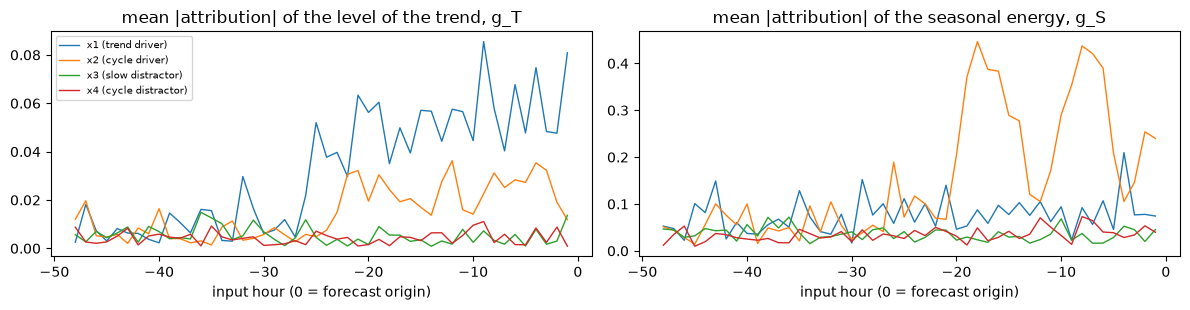

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2), sharex=True)
for ax, component, title in zip(axes, ("trend", "seasonal"), ("level of the trend, g_T", "seasonal energy, g_S")):
    mean_abs = attributions[component].abs().mean(dim=0).numpy()  # (L, d)
    for v, name in enumerate(VARIABLES):
        ax.plot(hours_in, mean_abs[:, v], label=name, lw=1)
    ax.set_title(f"mean |attribution| of the {title}")
    ax.set_xlabel("input hour (0 = forecast origin)")
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

In both panels the attributions concentrate on the last 24 input hours, the ones that set the next 24 values of the target.

### Without the decomposition

The usual practice explains one scalar of the whole forecast. Two common choices are the mean of the forecast (which equals
$g_T$) and the energy of the centered forecast, $\lVert\hat{\mathbf{y}}_c\rVert^2$. A single scalar gives a single ranking of
the inputs, so it cannot answer both questions: which input drives the trend, and which drives the cycle.

In [13]:
def whole_forecast_energy(x: torch.Tensor) -> torch.Tensor:
    forecast = model(x)["forecast"]
    return ((forecast - forecast.mean(dim=1, keepdim=True)) ** 2).sum(dim=1)


attr_energy = IntegratedGradients(whole_forecast_energy).attribute(x_explain, baselines=baseline, n_steps=100).detach()
share_energy = variable_shares(attr_energy)
for label, share in (("mean of the forecast (= g_T)", share_T), ("energy of the centered forecast", share_energy)):
    hit_trend = (share.argmax(1) == 0).double().mean().item()
    hit_cycle = (share.argmax(1) == 1).double().mean().item()
    print(f"{label:32s}: trend driver {hit_trend:4.0%}, cycle driver {hit_cycle:4.0%}")

mean of the forecast (= g_T)    : trend driver 100%, cycle driver   0%
energy of the centered forecast : trend driver  31%, cycle driver  69%


## 6. Caveats

* The decomposition is unique given the forecast, but what the network puts into each component depends on training. Check
  the coverage $\kappa$ before reading $\mathbf{T}$ and $\mathbf{S}$ as trend and seasonality.
* $g_S$ and $g_R$ are sums of squares. A positive attribution means that the input raises the energy of the component
  relative to the baseline; it does not mean that it raises the cycle.
* The baseline matters, as for any use of Integrated Gradients. Here it is the training mean of every variable.
* The same forward functions work with other Captum methods (`Saliency`, `FeatureAblation`, `KernelShap`, ...); only
  Integrated Gradients was checked for completeness here.
* Safe selection guarantees the dense model's accuracy on validation data only.
* The data and the model are small, so the numbers above illustrate the method. The experiments of [1] use eight real
  datasets and three backbones.